### Task 1: Designing a Heuristic for a Warehouse Robot

In [1]:
import math
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd


# 1. Coordinates of warehouse locations

locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6)
}


# 2. Weighted warehouse graph

warehouse_graph = {
    "Receiving_Area": {
        "Storage_A": 2.2,
        "Storage_B": 4.1
    },

    "Storage_A": {
        "Sorting_Area": 2.2
    },

    "Storage_B": {
        "Inspection_Area": 5.0,
        "Sorting_Area": 6.0
    },

    "Sorting_Area": {
        "Inspection_Area": 3.2,
        "Packing_Station": 5.0
    },

    "Inspection_Area": {
        "Packing_Station": 2.2
    },

    "Packing_Station": {}
}


# 3. Euclidean heuristic

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)


# 4. Calculate heuristic values

goal = "Packing_Station"

heuristic_data = []

for location in locations:
    heuristic_data.append({
        "Location": location,
        "Heuristic h(n)": round(heuristic(location, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)

print("Heuristic Values")
print("----------------")
print(heuristic_df.to_string(index=False))


Heuristic Values
----------------
       Location  Heuristic h(n)
 Receiving_Area            9.22
      Storage_A            7.07
      Storage_B            6.32
   Sorting_Area            5.00
Inspection_Area            2.24
Packing_Station            0.00


#### NetworkX visualization: Since Task 1 does not ask GBFS/A* to find a path, you are supposed highlight the actual minimum-cost path merely for visualization:

In [2]:
# 5. Create NetworkX graph

G = nx.DiGraph()

for node, neighbors in warehouse_graph.items():
    G.add_node(node, pos=locations[node])
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

# 6. Find minimum-cost path

solution_path = nx.shortest_path(
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

solution_cost = nx.shortest_path_length(
    G,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight"
)

print("\nMinimum cost path:")
print(" -> ".join(solution_path))
print(f"Total cost: {solution_cost:.2f}")



Minimum cost path:
Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 9.40


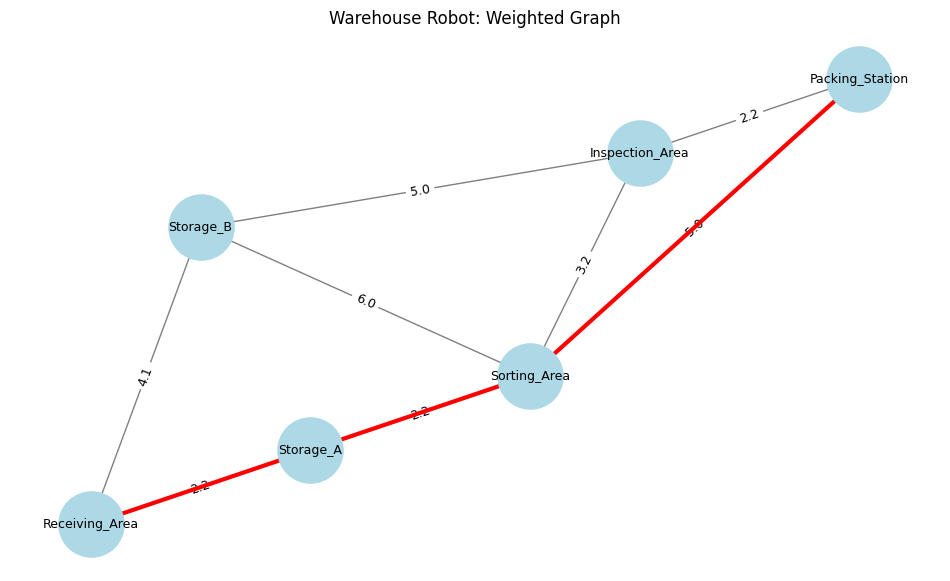

In [3]:
# 7. Visualize graph

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="lightblue",
    node_size=2200
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

solution_edges = list(zip(solution_path, solution_path[1:]))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=solution_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=22
)

plt.title("Warehouse Robot: Weighted Graph")
plt.axis("off")
plt.show()


In [4]:
# 8. Verify heuristic condition

print("\nHeuristic Condition Verification")
print("***********************************")

for node in warehouse_graph:
    for neighbor, cost in warehouse_graph[node].items():
        left = heuristic(node, goal)
        right = cost + heuristic(neighbor, goal)
        condition = left <= right

        print(
            f"{node} -> {neighbor}: "
            f"h({node}) = {left:.2f}, "
            f"cost + h({neighbor}) = {right:.2f}, "
            f"Condition = {condition}"
        )



Heuristic Condition Verification
***********************************
Receiving_Area -> Storage_A: h(Receiving_Area) = 9.22, cost + h(Storage_A) = 9.27, Condition = True
Receiving_Area -> Storage_B: h(Receiving_Area) = 9.22, cost + h(Storage_B) = 10.42, Condition = True
Storage_A -> Sorting_Area: h(Storage_A) = 7.07, cost + h(Sorting_Area) = 7.20, Condition = True
Storage_B -> Inspection_Area: h(Storage_B) = 6.32, cost + h(Inspection_Area) = 7.24, Condition = True
Storage_B -> Sorting_Area: h(Storage_B) = 6.32, cost + h(Sorting_Area) = 11.00, Condition = True
Sorting_Area -> Inspection_Area: h(Sorting_Area) = 5.00, cost + h(Inspection_Area) = 5.44, Condition = True
Sorting_Area -> Packing_Station: h(Sorting_Area) = 5.00, cost + h(Packing_Station) = 5.00, Condition = True
Inspection_Area -> Packing_Station: h(Inspection_Area) = 2.24, cost + h(Packing_Station) = 2.20, Condition = False


Observation: Euclidean distance is a natural geometric estimate of the remaining distance, but the given rounded edge cost Inspection_Area -> Packing_Station = 2.2 is slightly smaller than its Euclidean distance (2.24), so that edge does not satisfy the stated consistency condition.

### Task 2: Greedy Best-First Search for Airport Baggage Handling

In [5]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt

# 1. Airport coordinates

locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6)
}

# 2. Weighted graph

airport_graph = {
    "Baggage_Area": {
        "Security": 2.2,
        "Checkpoint": 4.1
    },

    "Security": {
        "Food_Court": 2.2
    },

    "Checkpoint": {
        "Terminal_Hall": 5.0
    },

    "Food_Court": {
        "Terminal_Hall": 3.2,
        "Departure_Gate": 6.0
    },

    "Terminal_Hall": {
        "Departure_Gate": 3.2
    },

    "Departure_Gate": {}
}

# 3. Euclidean heuristic

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)


# 4. GBFS

def greedy_best_first_search(start, goal, graph):
    frontier = []
    counter = 0

    heapq.heappush(
        frontier,
        (heuristic(start, goal), counter, start)
    )

    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in came_from:
                counter += 1
                came_from[neighbor] = current

                heapq.heappush(
                    frontier,
                    (
                        heuristic(neighbor, goal),
                        counter,
                        neighbor
                    )
                )

    if goal not in came_from:
        return None, None, expansion_order

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = came_from[current]

    path.reverse()

    total_cost = 0

    for i in range(len(path) - 1):
        total_cost += graph[path[i]][path[i + 1]]

    return path, total_cost, expansion_order


# 5. Run GBFS

start = "Baggage_Area"
goal = "Departure_Gate"

path, total_cost, expansion_order = greedy_best_first_search(
    start,
    goal,
    airport_graph
)

print("GBFS")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")

print(
    "\nExplanation: GBFS selects the frontier node with the smallest "
    "Euclidean distance to the Departure Gate. From Baggage_Area, "
    "Checkpoint is estimated closer to the goal than Security, so "
    "GBFS explores Checkpoint first."
)


GBFS
--------------------------------
Expansion order:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Solution path:
Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate

Total path cost: 12.30

Explanation: GBFS selects the frontier node with the smallest Euclidean distance to the Departure Gate. From Baggage_Area, Checkpoint is estimated closer to the goal than Security, so GBFS explores Checkpoint first.


#### NetworkX visualization

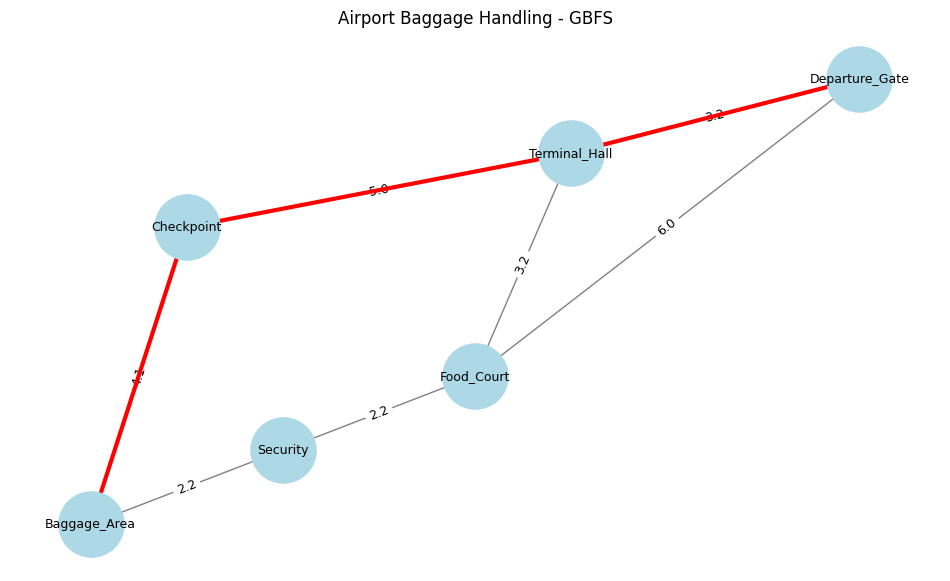

In [6]:
# 6. NetworkX visualization

G = nx.DiGraph()

for node, neighbors in airport_graph.items():
    G.add_node(node, pos=locations[node])
    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="lightblue",
    node_size=2200
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

solution_edges = list(zip(path, path[1:]))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=solution_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=22
)

plt.title("Airport Baggage Handling - GBFS")
plt.axis("off")
plt.show()


### Task 3: A* Search for Emergency Supply Robot

In [7]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt


# 1. Hospital coordinates

locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6)
}


# 2. Hospital weighted graph

hospital_graph = {
    "Pharmacy": {
        "Main_Corridor": 2.2,
        "Patient_Wing": 4.1
    },

    "Main_Corridor": {
        "Nursing_Station": 2.2
    },

    "Patient_Wing": {
        "Laboratory": 5.0
    },

    "Nursing_Station": {
        "Laboratory": 3.2,
        "Emergency_Ward": 6.0
    },

    "Laboratory": {
        "Emergency_Ward": 3.2
    },

    "Emergency_Ward": {}
}


# 3. Euclidean heuristic

def heuristic(current, goal):
    x1, y1 = locations[current]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)


# 4. Path reconstruction

def reconstruct_path(came_from, current):
    path = []

    while current is not None:
        path.append(current)
        current = came_from[current]

    path.reverse()
    return path


# 5. A* Search

def a_star_search(start, goal, graph):
    frontier = []
    counter = 0

    heapq.heappush(
        frontier,
        (
            heuristic(start, goal),
            counter,
            start
        )
    )

    g_cost = {start: 0.0}
    came_from = {start: None}
    expansion_order = []
    expanded = set()

    while frontier:
        _, _, current = heapq.heappop(frontier)

        if current in expanded:
            continue

        expanded.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_cost[current] + edge_cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                counter += 1

                f_cost = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    frontier,
                    (
                        f_cost,
                        counter,
                        neighbor
                    )
                )

    if goal not in came_from:
        return None, None, expansion_order, g_cost

    path = reconstruct_path(came_from, goal)

    return path, g_cost[goal], expansion_order, g_cost


# 6. Run A*

start = "Pharmacy"
goal = "Emergency_Ward"

path, total_cost, expansion_order, g_cost = a_star_search(
    start,
    goal,
    hospital_graph
)

print("A* Search")
print("--------------------------------")

print("Expansion order:")
print(" -> ".join(expansion_order))

print("\nSolution path:")
print(" -> ".join(path))

print(f"\nTotal path cost: {total_cost:.2f}")


A* Search
--------------------------------
Expansion order:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Solution path:
Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward

Total path cost: 10.40


#### g(n), h(n), f(n) table

In [8]:
# you may also replace it with dataframe it is completely your own choice

print("\nA* Node Information")
print("*********************")
print(
    f"{'Node':20s}"
    f"{'g(n)':>10s}"
    f"{'h(n)':>10s}"
    f"{'f(n)':>10s}"
)

for node in expansion_order:

    g = g_cost[node]
    h = heuristic(node, goal)
    f = g + h

    print(
        f"{node:20s}"
        f"{g:10.2f}"
        f"{h:10.2f}"
        f"{f:10.2f}"
    )



A* Node Information
*********************
Node                      g(n)      h(n)      f(n)
Pharmacy                  0.00     10.00     10.00
Main_Corridor             2.20      7.81     10.01
Nursing_Station           4.40      5.66     10.06
Emergency_Ward           10.40      0.00     10.40


#### NetworkX visualization

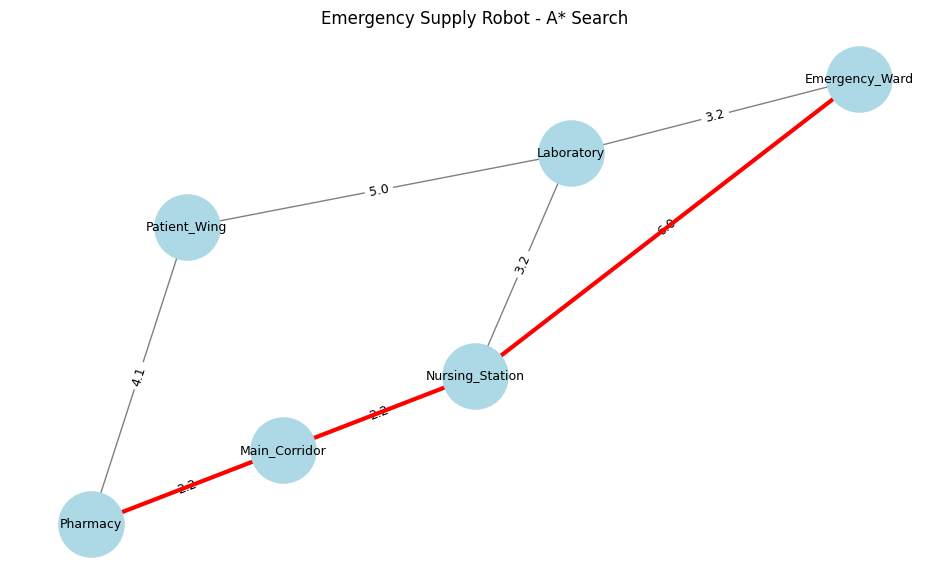

In [9]:
# 7. NetworkX visualization
G = nx.DiGraph()

for node, neighbors in hospital_graph.items():
    G.add_node(node, pos=locations[node])

    for neighbor, weight in neighbors.items():
        G.add_edge(node, neighbor, weight=weight)

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="lightblue",
    node_size=2200
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

solution_edges = list(zip(path, path[1:]))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=solution_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=22
)

plt.title("Emergency Supply Robot - A* Search")
plt.axis("off")
plt.show()


A* considers both the actual cost already travelled, g(n), and the estimated remaining cost, h(n). GBFS considers only h(n). Therefore, A* can avoid a node that appears close to the goal if reaching that node has already accumulated a larger path cost.

### Task 4: Weighted A* for Autonomous Delivery Drone

In [10]:
import math
import heapq
import pandas as pd

# 1. Location Coordinates

locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6)
}

# 2. Weighted Graph

graph = {
    "Distribution_Center": {
        "Zone_A": 2.2,
        "Zone_B": 3.0
    },

    "Zone_A": {
        "Zone_C": 2.2
    },

    "Zone_B": {
        "Zone_D": 5.0
    },

    "Zone_C": {
        "Zone_D": 3.2,
        "Customer_Building": 6.0
    },

    "Zone_D": {
        "Customer_Building": 3.2
    },

    "Customer_Building": {}
}

# 3. Euclidean Heuristic

def heuristic(node, goal):
    x1, y1 = locations[node]
    x2, y2 = locations[goal]
    return math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)

# 4. Display Heuristic Values

goal = "Customer_Building"

heuristic_data = []

for node in locations:

    heuristic_data.append({
        "Node": node,
        "h(n)": round(heuristic(node, goal), 2)
    })

heuristic_df = pd.DataFrame(heuristic_data)

print("Heuristic Values:")
print(heuristic_df.to_string(index=False))

# 5. Weighted A* Search
# f(n) = g(n) + w * h(n)

def weighted_a_star(start, goal, graph, weight):
    frontier = []
    counter = 0

    heapq.heappush(
        frontier,
        (
            weight * heuristic(start, goal),
            counter,
            start
        )
    )

    g_cost = {start: 0.0}
    came_from = {start: None}
    expansion_order = []
    expanded = set()

    while frontier:
        _, _, current = heapq.heappop(frontier)

        if current in expanded:
            continue

        expanded.add(current)
        expansion_order.append(current)

        if current == goal:
            break

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_cost[current] + edge_cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                counter += 1

                f_cost = tentative_g + weight * heuristic(
                    neighbor,
                    goal
                )

                heapq.heappush(
                    frontier,
                    (
                        f_cost,
                        counter,
                        neighbor
                    )
                )

    if goal not in came_from:
        return None, None, expansion_order

    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = came_from[current]

    path.reverse()

    return path, g_cost[goal], expansion_order


# 6. Run Weighted A* for All Required Weights

start = "Distribution_Center"
goal = "Customer_Building"

weights = [1, 1.5, 2, 3]

results = []

for w in weights:

    path, cost, expansion_order = weighted_a_star(
        start,
        goal,
        graph,
        w
    )

    results.append({
        "Weight": w,
        "Solution Path": " → ".join(path),
        "Total Cost": round(cost, 2),
        "Nodes Expanded": len(expansion_order),
        "Expansion Order": " → ".join(expansion_order)
    })


# 7. Display Results in dataframe

results_df = pd.DataFrame(results)

print("\nWeighted A* Results")
print(results_df.to_string(index=False))


# 8. Display Detailed Expansion Orders

print("\nDetailed Expansion Orders")
print("-------------------------")

for result in results:
    print(
        f"w = {result['Weight']}: "
        f"{result['Expansion Order']}"
    )


print(
    "\nAnalysis: As w increases, the heuristic receives greater "
    "importance in f(n) = g(n) + w*h(n). In this graph, higher "
    "weights cause the search to select the Zone_B -> Zone_D route, "
    "which has a higher total cost than the normal A* route."
)

print(
    "Normal A* with w = 1 balances g(n) and h(n). "
    "Weighted A* with w > 1 trusts the heuristic more and therefore "
    "does not have the same optimality guarantee."
)


Heuristic Values:
               Node  h(n)
Distribution_Center 10.00
             Zone_A  7.81
             Zone_B  7.28
             Zone_C  5.66
             Zone_D  3.16
  Customer_Building  0.00



Weighted A* Results
 Weight                                             Solution Path  Total Cost  Nodes Expanded                                                    Expansion Order
    1.0 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               5 Distribution_Center → Zone_A → Zone_C → Zone_B → Customer_Building
    1.5 Distribution_Center → Zone_A → Zone_C → Customer_Building        10.4               4          Distribution_Center → Zone_A → Zone_C → Customer_Building
    2.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4          Distribution_Center → Zone_B → Zone_D → Customer_Building
    3.0 Distribution_Center → Zone_B → Zone_D → Customer_Building        11.2               4          Distribution_Center → Zone_B → Zone_D → Customer_Building

Detailed Expansion Orders
-------------------------
w = 1: Distribution_Center → Zone_A → Zone_C → Zone_B → Customer_Building
w = 1.5: Distribution_Center → Zone_A → Zone_C 

#### NetworkX visualization

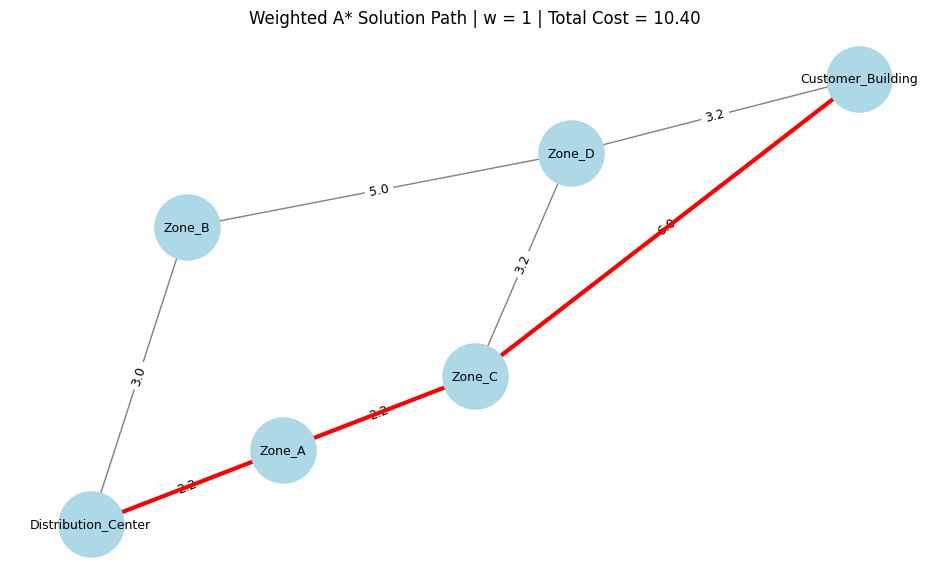

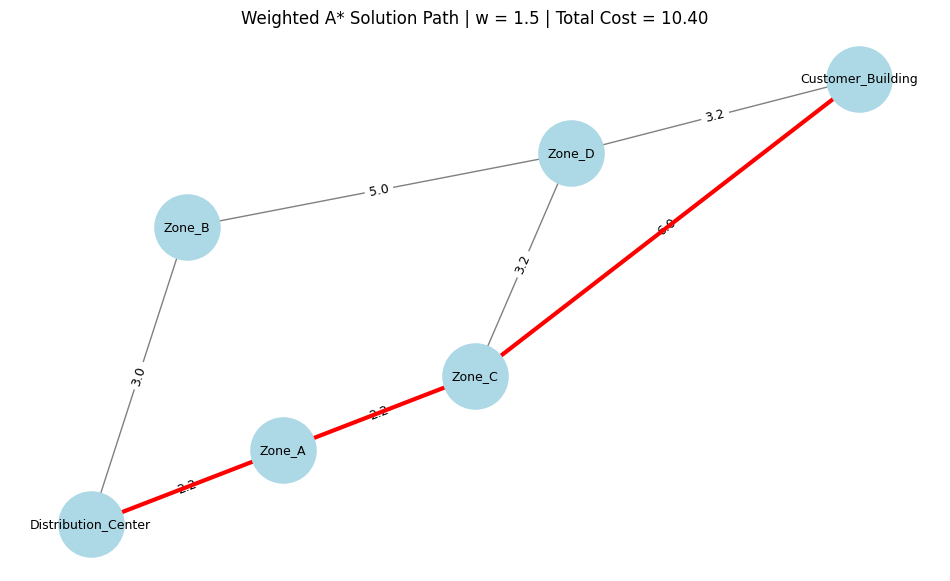

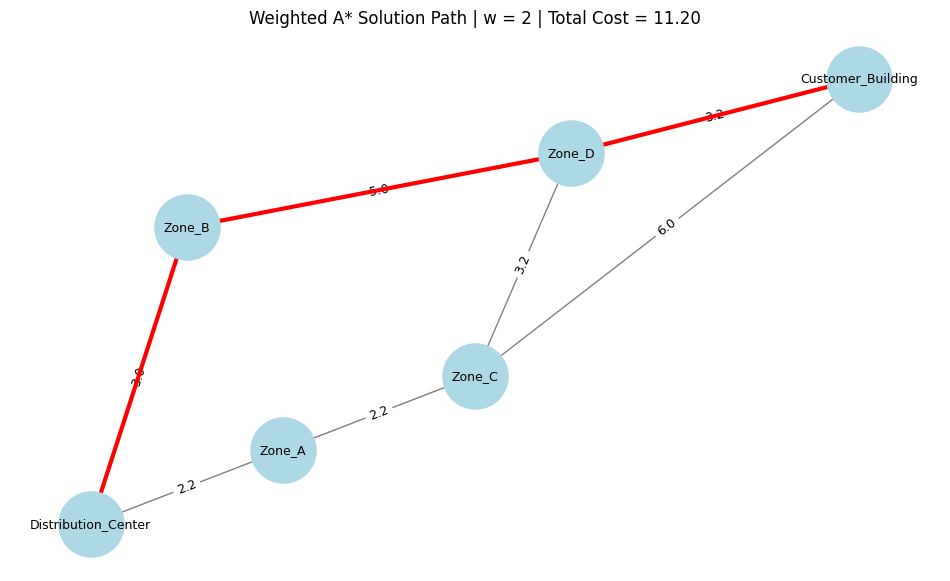

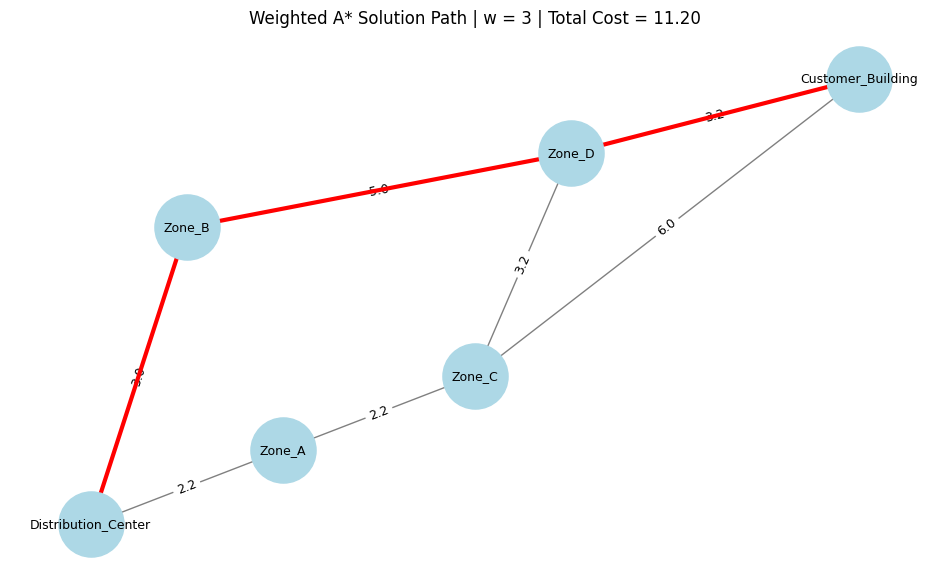

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Create NetworkX Graph

G = nx.DiGraph()

# Add nodes with their coordinates
for node, position in locations.items():

    G.add_node(
        node,
        pos=position
    )


# Add weighted edges
for node, neighbors in graph.items():

    for neighbor, cost in neighbors.items():
        G.add_edge(
            node,
            neighbor,
            weight=cost
        )

# 2. Node Positions
pos = locations

# 3. Visualize Weighted A* Result for Each Weight

for w in weights:

    path, cost, expansion_order = weighted_a_star(
        start,
        goal,
        graph,
        w
    )

    plt.figure(figsize=(12, 7))

    nx.draw_networkx_nodes(
        G,
        pos,
        node_color="lightblue",
        node_size=2200
    )

    nx.draw_networkx_edges(
        G,
        pos,
        edge_color="gray",
        arrows=True,
        arrowsize=20
    )

    nx.draw_networkx_labels(
        G,
        pos,
        font_size=9
    )

    edge_labels = nx.get_edge_attributes(G, "weight")

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=9
    )

    solution_edges = list(zip(path, path[1:]))

    nx.draw_networkx_edges(
        G,
        pos,
        edgelist=solution_edges,
        edge_color="red",
        width=3,
        arrows=True,
        arrowsize=22
    )

    plt.title(
        f"Weighted A* Solution Path | w = {w} | "
        f"Total Cost = {cost:.2f}"
    )

    plt.axis("off")

    plt.show()


#### Expansion order

This means:

In what order did the search algorithm remove/select nodes from the frontier and process them?

For example:

Expanded:
S → A → B → C → D → G

The algorithm may explore some nodes that are ultimately not part of the final route.

#### Solution path

This means:

Which nodes form the final route from start to goal?

For example:

Solution:
S → A → C → G

Here:

Expansion order:  S → A → B → C → D → G
Solution path:    S → A → C → G

### Task 5: Finding a Charging Station Using Multiple Goals

Part A: Greedy Best-First Search
--------------------------------
Expansion order:
Current_Location -> Junction_A -> Junction_C -> Charging_Central

Charging station reached:
Charging_Central

Solution path:
Current_Location -> Junction_A -> Junction_C -> Charging_Central

Total path cost: 8.40

Part B: A* Search
------------------
Expansion order:
Current_Location -> Junction_A -> Junction_C -> Charging_Central

Charging station reached:
Charging_Central

Solution path:
Current_Location -> Junction_A -> Junction_C -> Charging_Central

Total path cost: 8.40

Part C: GBFS vs A*
------------------
                 Measure                                                             GBFS                                                               A*
Charging station reached                                                 Charging_Central                                                 Charging_Central
           Solution path Current_Location -> Junction_A -> Junction_C -> Charging_Centr

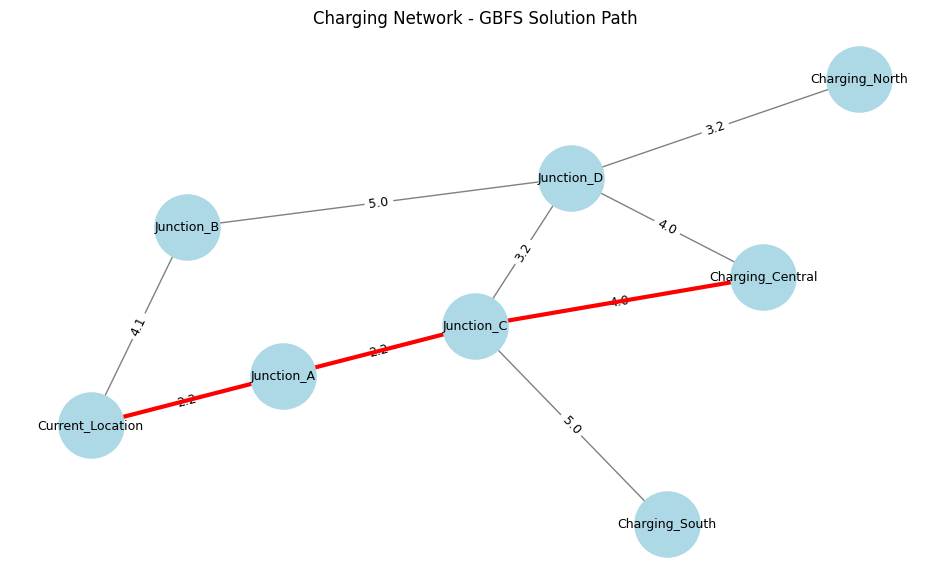

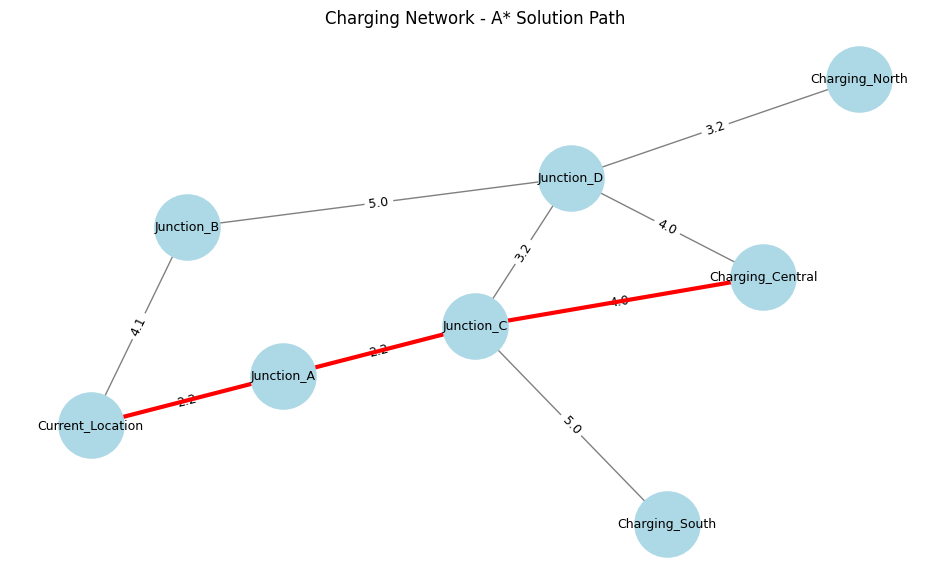

In [12]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charging network coordinates

locations = {
    "Current_Location": (0, 0),
    "Junction_A": (2, 1),
    "Junction_B": (1, 4),
    "Junction_C": (4, 2),
    "Junction_D": (5, 5),
    "Charging_North": (8, 7),
    "Charging_Central": (7, 3),
    "Charging_South": (6, -2)
}

charging_stations = {
    "Charging_North",
    "Charging_Central",
    "Charging_South"
}

# 2. Weighted charging network

charging_graph = {
    "Current_Location": {
        "Junction_A": 2.2,
        "Junction_B": 4.1
    },

    "Junction_A": {
        "Junction_C": 2.2
    },

    "Junction_B": {
        "Junction_D": 5.0
    },

    "Junction_C": {
        "Junction_D": 3.2,
        "Charging_Central": 4.0,
        "Charging_South": 5.0
    },

    "Junction_D": {
        "Charging_North": 3.2,
        "Charging_Central": 4.0
    },

    "Charging_North": {},
    "Charging_Central": {},
    "Charging_South": {}
}


# 3. Multiple-goal heuristic

def heuristic(node):
    return min(
        math.sqrt(
            (locations[node][0] - locations[station][0]) ** 2
            + (locations[node][1] - locations[station][1]) ** 2
        )
        for station in charging_stations
    )


# 4. GBFS for multiple goals

def greedy_best_first_search(start, graph):
    frontier = []
    counter = 0

    heapq.heappush(
        frontier,
        (heuristic(start), counter, start)
    )

    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current in charging_stations:
            break

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in came_from:
                counter += 1
                came_from[neighbor] = current

                heapq.heappush(
                    frontier,
                    (
                        heuristic(neighbor),
                        counter,
                        neighbor
                    )
                )

    if not expansion_order or expansion_order[-1] not in charging_stations:
        return None, None, None, expansion_order

    reached_station = expansion_order[-1]
    path = []
    current = reached_station

    while current is not None:
        path.append(current)
        current = came_from[current]

    path.reverse()

    total_cost = sum(
        graph[path[i]][path[i + 1]]
        for i in range(len(path) - 1)
    )

    return path, total_cost, reached_station, expansion_order


# 5. A* for multiple goals

def a_star_search(start, graph):
    frontier = []
    counter = 0

    heapq.heappush(
        frontier,
        (
            heuristic(start),
            counter,
            start
        )
    )

    g_cost = {start: 0.0}
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)

        if current in visited:
            continue

        visited.add(current)
        expansion_order.append(current)

        if current in charging_stations:
            break

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_cost[current] + edge_cost

            if neighbor not in g_cost or tentative_g < g_cost[neighbor]:
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                counter += 1

                f_cost = tentative_g + heuristic(neighbor)

                heapq.heappush(
                    frontier,
                    (
                        f_cost,
                        counter,
                        neighbor
                    )
                )

    if not expansion_order or expansion_order[-1] not in charging_stations:
        return None, None, None, expansion_order

    reached_station = expansion_order[-1]
    path = []
    current = reached_station

    while current is not None:
        path.append(current)
        current = came_from[current]

    path.reverse()

    return (
        path,
        g_cost[reached_station],
        reached_station,
        expansion_order
    )


# 6. Run GBFS

start = "Current_Location"

gbfs_path, gbfs_cost, gbfs_station, gbfs_expansion = (
    greedy_best_first_search(
        start,
        charging_graph
    )
)

print("Part A: Greedy Best-First Search")
print("--------------------------------")
print("Expansion order:")
print(" -> ".join(gbfs_expansion))
print("\nCharging station reached:")
print(gbfs_station)
print("\nSolution path:")
print(" -> ".join(gbfs_path))
print(f"\nTotal path cost: {gbfs_cost:.2f}")


# 7. Run A*

astar_path, astar_cost, astar_station, astar_expansion = (
    a_star_search(
        start,
        charging_graph
    )
)

print("\nPart B: A* Search")
print("------------------")
print("Expansion order:")
print(" -> ".join(astar_expansion))
print("\nCharging station reached:")
print(astar_station)
print("\nSolution path:")
print(" -> ".join(astar_path))
print(f"\nTotal path cost: {astar_cost:.2f}")


# 8. Comparison table

comparison_df = pd.DataFrame([
    {
        "Measure": "Charging station reached",
        "GBFS": gbfs_station,
        "A*": astar_station
    },
    {
        "Measure": "Solution path",
        "GBFS": " -> ".join(gbfs_path),
        "A*": " -> ".join(astar_path)
    },
    {
        "Measure": "Total path cost",
        "GBFS": round(gbfs_cost, 2),
        "A*": round(astar_cost, 2)
    },
    {
        "Measure": "Number of nodes expanded",
        "GBFS": len(gbfs_expansion),
        "A*": len(astar_expansion)
    }
])

print("\nPart C: GBFS vs A*")
print("------------------")
print(comparison_df.to_string(index=False))

print(
    "\nAnalysis: Both algorithms use the same nearest-station "
    "heuristic, but GBFS uses only h(n), while A* uses g(n) + h(n). "
    "Therefore, A* also considers the cost already travelled and can "
    "make different search decisions."
)


# 9. NetworkX visualization

G = nx.DiGraph()

for node, position in locations.items():
    G.add_node(node, pos=position)

for node, neighbors in charging_graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

pos = locations

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="lightblue",
    node_size=2200
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

edge_labels = nx.get_edge_attributes(G, "weight")

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

gbfs_edges = list(zip(gbfs_path, gbfs_path[1:]))
astar_edges = list(zip(astar_path, astar_path[1:]))

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=gbfs_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=22
)

plt.title("Charging Network - GBFS Solution Path")
plt.axis("off")
plt.show()

plt.figure(figsize=(12, 7))

nx.draw_networkx_nodes(
    G,
    pos,
    node_color="lightblue",
    node_size=2200
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color="gray",
    arrows=True,
    arrowsize=20
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=9
)

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=astar_edges,
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=22
)

plt.title("Charging Network - A* Solution Path")
plt.axis("off")
plt.show()
